# 05 — The extinction flow, its Laplace dual, the order of approach, the nodal ladder, and what 0_RB says about ζ

**Assistant note.** Written by an AI assistant (Claude) with the author, from `rhp/extinction.py`, `rhp/nodal.py`, `rhp/zerorb.py` and the figures in `rhp/atlas_riemann_fermat/`
(`flow.svg`, `net.svg`, `nodal.svg`, `flow_player.html`). Labels: ESTABLISHED, OURS, THEORETICAL, CONJECTURE, OPEN; `:CALCULATED` = this code reproduces it.
**This sets up a space and machinery; it proves nothing about RH.**

**Vantage point.** Working axis u = ln x (the Archimedes Screw's own); time of the flow τ = ln y; dual variable s′ = s − 1 (Laplace conjugate of u).
Aperture: integers ≤ 2·10⁶ for the flow; ξ on σ ∈ [−1.5, 2.5], t ≤ 50 for the ladder.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, math
from IPython.display import SVG, display
from rhp import extinction as X, nodal as N, wrap as W, zerorb as Z

## 1  The two books as continuous flows (ESTABLISHED: Buchstab ω, Dickman ρ, Mertens)

rho(2) = 0.30685280381505586  exact 1-ln2 = 0.3068528194400547
omega(3) = 0.5643823987283152  exact (1+ln2)/3 = 0.5643823935199818  limit e^-gamma = 0.5614594835668851
U=2: survivors*ln y/N = 0.5411   omega = 0.5000   | smooth/N = 0.3443  rho = 0.3069
U=3: survivors*ln y/N = 0.5561   omega = 0.5644   | smooth/N = 0.0723  rho = 0.0486


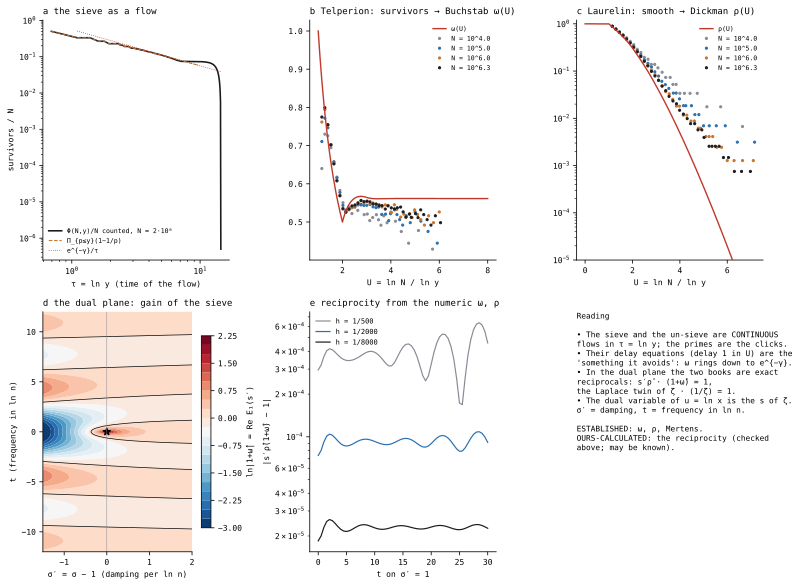

In [2]:
ur, r = X.dickman(); uo, o = X.buchstab()
at = lambda u, a, x: a[int(round(x / (u[1] - u[0])))]
print("rho(2) =", at(ur, r, 2), " exact 1-ln2 =", 1 - math.log(2))
print("omega(3) =", at(uo, o, 3), " exact (1+ln2)/3 =", (1 + math.log(2)) / 3, " limit e^-gamma =", math.exp(-X.GAMMA))
N_ = 1_000_000
spf, gpf = W.spf_gpf(N_)
for U in (2, 3):
    y = N_ ** (1 / U)
    print(f"U={U}: survivors*ln y/N = {X.survivors(spf, N_, y) * math.log(y) / N_:.4f}   omega = {at(uo, o, U):.4f}   | smooth/N = {X.smooth(gpf, N_, y) / N_:.4f}  rho = {at(ur, r, U):.4f}")
display(SVG("../rhp/atlas_riemann_fermat/flow.svg"))

Finite-N points sit below ω and above ρ by O(1/ln y); that is the known slow convergence, not a failure.
Open `../rhp/atlas_riemann_fermat/flow_player.html` in a browser to drag τ and watch each integer die (blue→grey) and be born (orange ring).

## 2  The Laplace dual: the two books are reciprocal  (OURS-CALCULATED)
ρ̂(s) = e^{−E₁(s)}/s and 1 + ω̂(s) = e^{+E₁(s)}, so **s·ρ̂(s)·(1 + ω̂(s)) = 1** — the Laplace twin of ζ·(1/ζ) = 1 (1/ζ = Σμ(n)n⁻ˢ is the sieve).
Derived from (uω)′ = ω(u−1) and uρ′ = −ρ(u−1); checked below from the NUMERIC solutions, error first order in the grid step. Not found stated this way; may be known.

In [3]:
for h in (1/500, 1/2000, 1/8000):
    a, b = X.dickman(14, h), X.buchstab(14, h)
    print(f"h=1/{round(1/h)}:", [f"{X.reciprocal_residual(s, a[0], a[1], b[0], b[1]):.1e}" for s in (0.5, 1.0, 0.7+3j, 1+10j)])

h=1/500: ['3.5e-04', '3.0e-04', '5.4e-04', '3.9e-04']
h=1/2000: ['8.7e-05', '7.4e-05', '1.3e-04', '9.3e-05']
h=1/8000: ['2.2e-05', '1.8e-05', '3.4e-05', '2.3e-05']


## 3  Order of approach: the two paths by which a number is reached (OURS reading; the numbers are measured)

In [4]:
for n in (12, 360, 49, 97, 1001):
    print(n, X.approach_paths(n), "span ln(gpf/spf) = %.3f" % X.span(n))
w = np.log(gpf[2:] / spf[2:])
print("integers <= 1e6 with span 0 (prime powers):", int(np.sum(w == 0)), "of", len(w), "; mean span of the rest %.2f e-folds" % w[w > 0].mean())
from scipy.stats import spearmanr
n_ = np.arange(2, 200002)
print("rank correlation of size with birth order (gpf): %.3f ; with death order (spf): %.3f" % (spearmanr(n_, gpf[2:200002])[0], spearmanr(n_, spf[2:200002])[0]))

12 ([2, 2, 3], [3, 2, 2]) span ln(gpf/spf) = 0.405
360 ([2, 2, 2, 3, 3, 5], [5, 3, 3, 2, 2, 2]) span ln(gpf/spf) = 0.916
49 ([7, 7], [7, 7]) span ln(gpf/spf) = 0.000
97 ([97], [97]) span ln(gpf/spf) = 0.000
1001 ([7, 11, 13], [13, 11, 7]) span ln(gpf/spf) = 0.619
integers <= 1e6 with span 0 (prime powers): 78734 of 999999 ; mean span of the rest 6.55 e-folds
rank correlation of size with birth order (gpf): 0.218 ; with death order (spf): 0.008


A number is the same multiset of primes read in two opposite orders: ascending (the sieve strips the smallest first) and descending (the wheels finish it by switching on the largest last).
They coincide only for prime powers. The size order of the integers is almost unrelated to either arrival order.
**READING, not a theorem:** the reversal of the order of approach is the candidate for what the north–south mirror s↦1−s does to a term (0_RB: R̂† = B̂).

## 4  The six faces of (u, τ, σ′, t)

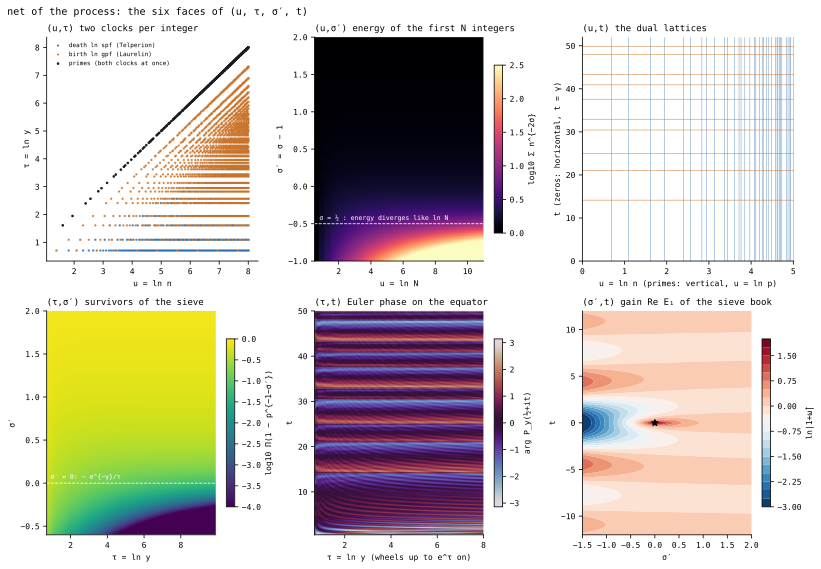

In [5]:
display(SVG("../rhp/atlas_riemann_fermat/net.svg"))

## 5  The nodal ladder, both hemispheres
ESTABLISHED: ξ(½+it) = F(t) is real; ∂ξ/∂σ = −iF′ there. OURS-CALCULATED here: for t ≤ 50 the curves Re ξ = 0 (through the zeros) and Im ξ = 0 (through F's extrema) alternate as a ladder of
near-horizontal rungs that cross only on the equator; the extrema are hyperbolic saddles (Hessian eigenvalues ±λ); no off-line crossing in the window tested.

10 zero rungs; 9 saddle rungs; one saddle between each consecutive pair: True
Hessian eigenvalues at first saddle: [-0.00044879  0.00044879]
off-line Re=Im=0 cells in sigma in [-0.6,1.6], t in [10,35]: []


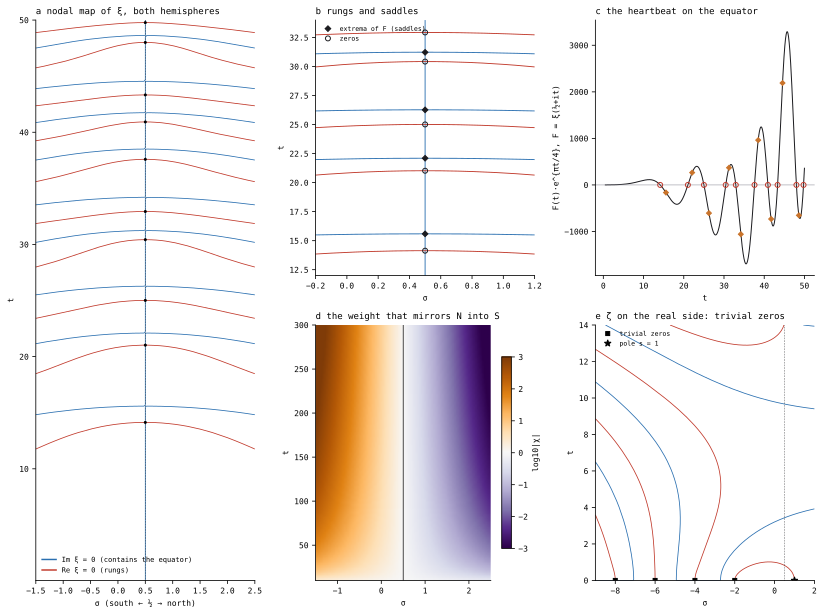

In [6]:
zs = N.rungs(50, 3000); ex = N.heartbeat_extrema(50, 3000)
print(len(zs), "zero rungs;", len(ex), "saddle rungs; one saddle between each consecutive pair:", all(sum(a < e < b for e in ex) == 1 for a, b in zip(zs[:-1], zs[1:])))
print("Hessian eigenvalues at first saddle:", N.saddle_hessian(ex[0]))
sig = np.linspace(-0.6, 1.6, 45); t = np.linspace(10, 35, 160)
print("off-line Re=Im=0 cells in sigma in [-0.6,1.6], t in [10,35]:", N.offline_crossings(sig, t, N.grid(sig, t)))
display(SVG("../rhp/atlas_riemann_fermat/nodal.svg"))

## 6  What 0_RB says about ζ (located 2026-11-07) and the tests against it
Where ζ lives in 0_RB: **Σ_RB = Σ_p p^{−σ}[R̂_p⊗∂̂ + ∂̂†⊗B̂_p]** (`h_rb_hat/maths.py`) — ζ is the coupling p^{−σ}; R̂† = B̂ is the functional equation; Red = x·p, Blue = ½p² + ℘.
The **Archimedes Screw** (`archimedes_screw/maths.py`) uses u = ln x, pitch ln p, ψ jumps by ln p at u = ln p, zeros are tones. **Prime/Factor wavelength** and **Ring-theory spine** are in `.clauderc_canonical_maths`.

In [7]:
print("screw: max |jump - ln p| over prime powers <= 200:", Z.jumps_at_ln_p(200))
for r in Z.screw_reconstruction((100.5,), (10, 50)): print("tabulated zeros  x=%.1f K=%d  exact %.3f  explicit %.3f  |err| %.3f" % r)
print("Sigma_RB balance / sum(G) at x=2, p=1.3, by sigma:", [round(v[1] / Z.load_hrb().sigma_rb_evaluate(v[0], 2.0, 1.3)['total_G'], 6) for v in Z.sigma_rb_balance_vs_sigma(2.0, 1.3)])
cut, tab = Z.dominance_table(100.0); print("cutoff sqrt(t/2pi) =", round(cut, 3)); [print(" ", k, v) for k, v in tab.items()]
for n in (2, 3, 5): print("n=%d: t=%.1f  zero spacing %.3f  wheel period %.3f  ratio %.3f  | measured spacing %.3f" % ((n,) + Z.wavelength_pair(n) + (Z.measured_spacing(n)[0],)))

screw: max |jump - ln p| over prime powers <= 200: 0.0
tabulated zeros  x=100.5 K=10  exact 94.045  explicit 95.776  |err| 1.731
tabulated zeros  x=100.5 K=50  exact 94.045  explicit 94.905  |err| 0.860
Sigma_RB balance / sum(G) at x=2, p=1.3, by sigma: [1.251667, 1.251667, 1.251667, 1.251667, 1.251667]
cutoff sqrt(t/2pi) = 3.989
  (0.25, 1) mirror (Blue) dominates
  (0.25, 2) mirror (Blue) dominates
  (0.25, 3) mirror (Blue) dominates
  (0.25, 4) forward (Red) dominates
  (0.75, 1) forward (Red) dominates
  (0.75, 2) forward (Red) dominates
  (0.75, 3) forward (Red) dominates
  (0.75, 4) mirror (Blue) dominates
n=2: t=25.1  zero spacing 4.532  wheel period 9.065  ratio 0.500  | measured spacing 4.700
n=3: t=56.5  zero spacing 2.860  wheel period 5.719  ratio 0.500  | measured spacing 2.725
n=5: t=157.1  zero spacing 1.952  wheel period 3.904  ratio 0.500  | measured spacing 1.926


**Findings.** (1) the Screw's explicit formula reproduces ψ from true zeros and its jumps are exactly ln p; (2) at n ≥ 51 its tabulated zero heights fall back to a Lambert approximation and drift by ≈ 2.3 — logged;
(3) Σ_RB's `balance` is (Σ_p p^{−σ})·(E_Red − E_Blue), so it vanishes on a σ-independent set and cannot select σ = ½ — logged;
(4) in each hemisphere the forward (Red) and mirror (Blue) waves swap dominance at n = √(t/2π), in opposite senses north and south (the polarisation ratio of notebook 04);
(5) at the resonance t = 2πn² the mean zero spacing is exactly half the n-th wheel's period, so λ_prime = λ_factor/2 there.

## 7  Anomaly log (Chase Every Anomaly)
| # | Anomaly | Verdict |
|---|---|---|
| 1 | Writing `rhp/flow.py` overwrote the existing notebook-02 module | CODE (mine): restored from git; new module is `rhp/extinction.py` |
| 2 | Finite-N survivors/smooth points do not sit on ω/ρ | MATHS: O(1/ln y) known; shrinks with N |
| 3 | Reciprocity residual ~1e-4 | METHOD: first-order grid error at the jump ω(1⁻)=0→1; scales with h; closed forms agree to 1e-12 |
| 4 | Screw zeros after n = 50 off by ≈ 2.3 | CODE (ValaQuenta, not edited): Lambert approximation fallback |
| 5 | Σ_RB balance independent of σ | CODE/METHOD (ValaQuenta, not edited): σ enters only as a common weight |

## 8  The divergence detector (generational-lineage reading first)
**What it detects.** On the line every zero is a pure rotation in u = ln x (gain 1: isometries only). An off-line zero at ½+δ+iγ adds a growth e^{δu}: a DILATE, graded by δ — emergence signature 1 of §5
("a quantity that changes length where only isometries were in play"; graded, not one bit). Its mirror partner decays as e^{−δu}, so the amplitude at that frequency is a cosh and the slope is ~δ²u for small δ.
The equator is the fixed set of the mirror (tier 2, DERIVED); the detector reads the state of the balanced object — the Red/Blue amplitude ratio — not the fixed set itself.
**Order of work (§8):** control on the real ψ first, then injection of a known quadruple, then the detection limit. The null result on real ψ is a statement about the window u ≤ 16 only.

control slopes: mean -0.0174 sd 0.0328  -> 3 sd floor 0.098
inject & recover at gamma_1: [(0.05, 0.0175), (0.1, 0.0612), (0.2, 0.1743), (0.3, 0.2869), (0.5, 0.4971)]
reach u_max=11: delta_min(3sd) = 0.516 (floor sd 0.170)
reach u_max=13: delta_min(3sd) = 0.285 (floor sd 0.088)
reach u_max=16: delta_min(3sd) = 0.134 (floor sd 0.033)
control candidates: []
with delta=0.3 injected at 17.5: [(12.79999999999999, 0.155180030905505, 0.1619505169706352), (17.49999999999997, 3.9381091208256978, 0.2976486482324646)]


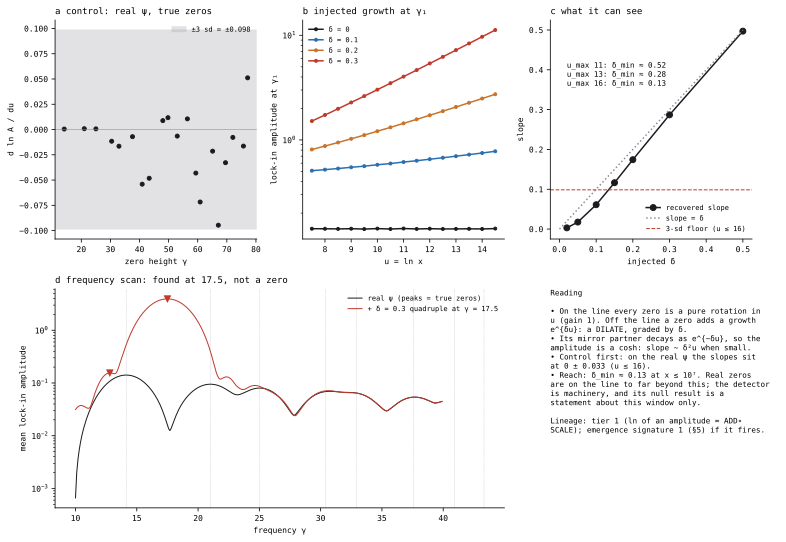

In [8]:
from rhp import diverge as D
psi = D.psi_table(10**7)
s, m, sd = D.control(psi, 20); print("control slopes: mean %.4f sd %.4f  -> 3 sd floor %.3f" % (m, sd, 3*sd))
print("inject & recover at gamma_1:", [(d, round(v, 4)) for d, v in D.inject_and_recover(psi, [0.05, 0.1, 0.2, 0.3, 0.5])])
for u1 in (11, 13, 16): print("reach u_max=%d: delta_min(3sd) = %.3f (floor sd %.3f)" % ((u1,) + D.detection_limit(psi, u1)))
g = np.arange(10, 40, 0.1); _, s0, a0 = D.scan(psi, g); _, s1, a1 = D.scan(psi, g, extra=lambda u: D.quadruple(u, 0.3, 17.5))
print("control candidates:", D.candidate_peaks(g, s0, a0, 0.1, 0.06)); print("with delta=0.3 injected at 17.5:", D.candidate_peaks(g, s1, a1, 0.1, 0.06))
display(SVG("../rhp/atlas_riemann_fermat/diverge.svg"))